In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

读取数据

In [33]:
df = pd.read_csv('german_credit_data.csv')
print(df.shape)
df.head()
print(df['kredit'].value_counts())

(1000, 21)
1    700
0    300
Name: kredit, dtype: int64


数据处理，令 label=1 表示违约

In [34]:
df['label'] = (df['kredit'] == 0).astype(int)
y = df['label']
X = df.drop(columns=['kredit', 'label'])
print(X.shape)

(1000, 20)


划分测试集

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

特征标准化

In [36]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

训练模型

In [37]:
model = SVC(kernel='rbf', C=10, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

SVC(C=10, class_weight='balanced', random_state=42)

预测并评估

In [38]:
y_pred = model.predict(X_test)
print('准确率:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['按时还款', '违约']))

准确率: 0.71
              precision    recall  f1-score   support

        按时还款       0.81      0.77      0.79       210
          违约       0.52      0.57      0.54        90

    accuracy                           0.71       300
   macro avg       0.66      0.67      0.66       300
weighted avg       0.72      0.71      0.71       300



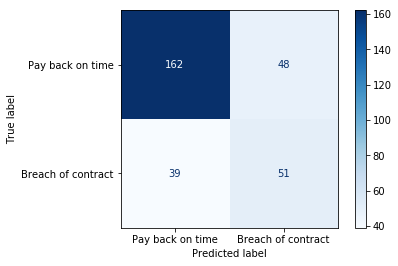

In [39]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Pay back on time', 'Breach of contract'], cmap='Blues')
plt.show()